# 06 — Model performance

Two questions decide whether a scorecard is fit for use:

1. **Does it rank customers correctly?** Bads should get lower scores than goods. Measured by AUC, Gini and KS.
2. **Are its PDs right?** If it says 20%, about 20% of those customers should default. Measured by calibration.

| Measure | Plain-language meaning | Scale |
|---|---|---|
| **AUC** | Pick one good and one bad customer at random. AUC is the chance the good one has the higher score. | 0.5 = coin toss, 1 = always right |
| **Gini** | 2 × AUC − 1. The same information on a 0-to-1 scale; the headline number in credit risk. | 0 = random, 1 = perfect |
| **KS** | The biggest gap between "% of bads at or below a score" and "% of goods at or below it". How well one cut-off could split them. | 0 = no separation, 1 = perfect |

AUC, Gini and KS are measured on the **scorecard scores**, the product a bank would use. Calibration uses the model's
**PDs**, because only a probability can be compared with an actual default rate. The test set has never been used for any decision.

Run notebooks 02–05 first.

In [1]:
import logging

import pandas as pd
import matplotlib.pyplot as plt

from scorecard.binning import load_binnings
from scorecard.data import MODELS_DIR, PROCESSED_DIR, REPORTS_DIR
from scorecard.metrics import (
    bootstrap_gini,
    calibration_table,
    ks_table,
    overfitting_verdict,
    performance_summary,
    roc_points,
)
from scorecard.plots import plot_calibration, plot_ks, plot_roc
from scorecard.scaling import score_customers

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)

scorecard = pd.read_csv(REPORTS_DIR / "scorecard.csv")
binnings = load_binnings(MODELS_DIR / "binnings.pkl")
samples = {}
for name in ["train", "test"]:
    data = pd.read_csv(PROCESSED_DIR / f"{name}.csv")
    pds = pd.read_csv(PROCESSED_DIR / f"{name}_pd.csv")
    assert (data["id"].values == pds["id"].values).all()
    samples[name.capitalize()] = {"default": data["default"], "pd": pds["pd"],
                                  "score": score_customers(data, scorecard, binnings)}

## 1. AUC, Gini and KS on train and test

If a model has memorised its training data (**overfitting**), it scores much better on train than on test. Rule of thumb:
a Gini drop under 3 points is normal, 3–5 is worth watching, over 5 is overfitting.

A Gini measured on 9,000 customers would come out slightly different on another 9,000. The **95% range** comes from re-drawing
the sample 500 times (bootstrap) and shows how much of a difference could be chance.

In [2]:
rows = {}
for name, s in samples.items():
    summary = performance_summary(s["default"], s["score"])
    summary["gini_95_low"], summary["gini_95_high"] = bootstrap_gini(s["default"], s["score"])
    rows[name] = summary
performance = pd.DataFrame(rows).T
metric_columns = ["auc", "gini", "ks"]
performance.loc["Gap (train - test)", metric_columns] = (
    performance.loc["Train", metric_columns] - performance.loc["Test", metric_columns]
)
performance = performance.rename_axis("sample").reset_index()
performance.to_csv(REPORTS_DIR / "performance.csv", index=False)

verdict = overfitting_verdict(rows["Train"]["gini"], rows["Test"]["gini"])
logging.info(verdict)
performance.style.format({"customers": "{:,.0f}", "default_rate": "{:.2%}", "auc": "{:.3f}", "gini": "{:.3f}",
                          "gini_95_low": "{:.3f}", "gini_95_high": "{:.3f}", "ks": "{:.3f}",
                          "ks_score": "{:.0f}"}, na_rep="")

INFO root: Watch: test Gini is 3.5 points below train.


,sample,customers,default_rate,auc,gini,ks,ks_score,gini_95_low,gini_95_high
0,Train,"21,000",22.12%,0.776,0.551,0.421,518,0.535,0.567
1,Test,"9,000",22.12%,0.758,0.517,0.402,517,0.493,0.542
2,Gap (train - test),,,0.017,0.035,0.018,,,


**Verdict: watch, not overfitting.**
- On test, **Gini 0.517** (AUC 0.758) and **KS 0.40**, against 0.552 and 0.42 on train.
- The 3.5-point Gini drop is just inside the "watch" zone. The bootstrap shows the test Gini alone could move by about
  ±2.5 points by chance, so part of the gap is noise. The train Gini (0.552) sits just above the test range (0.493–0.542), so
  part of it is real: the bins and the variable selection were fitted on training customers, and they fit those slightly better.
- **0.52 is the number to quote,** because it comes from customers the model has never seen.
- Scores are rounded points, but the model's unrounded PDs give almost the same test Gini (0.518), so rounding costs nothing meaningful.

## 2. ROC curve (test set)

The ROC curve shows every possible cut-off at once. Moving the cut-off up the score range flags more bads (up the y-axis) but also
more goods (along the x-axis). A useless model follows the diagonal. The further the curve bows towards the top-left, the better.
Gini is the shaded area between the curve and the diagonal, doubled.

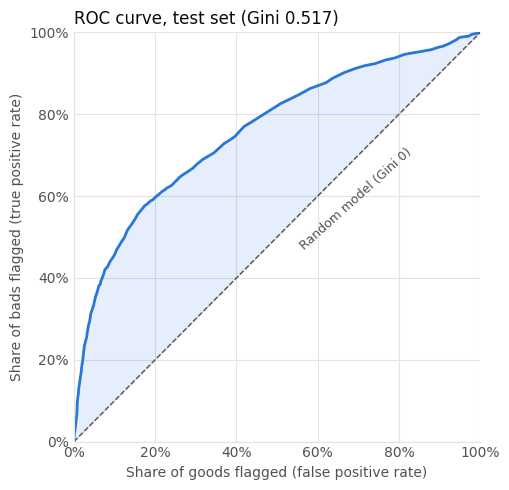

In [3]:
test = samples["Test"]
plot_roc(roc_points(test["default"], test["score"]), rows["Test"]["gini"], "test set")
plt.show()

The curve rises steeply at the start. The lowest-scoring customers are overwhelmingly bad, so a strict cut-off catches many bads while
flagging few goods. It then flattens: past a point, catching the remaining bads costs a lot of goods. Those are the
bads with a clean history that the scorecard can't distinguish.

## 3. KS chart (test set)

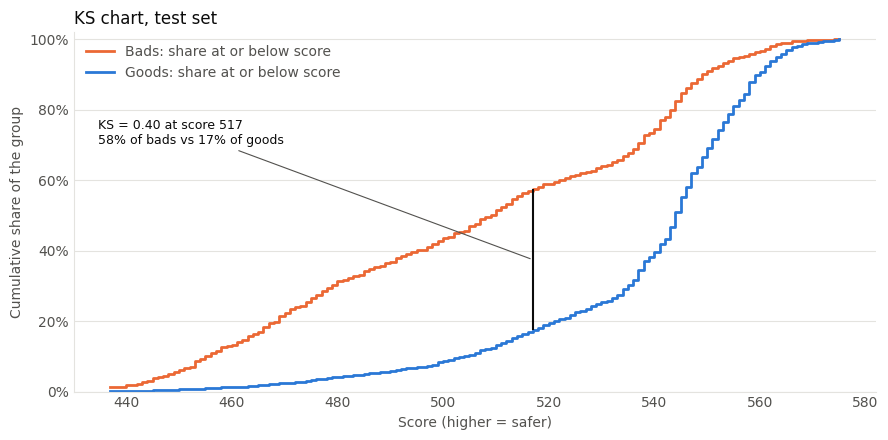

In [4]:
table = ks_table(test["default"], test["score"])
plot_ks(table, rows["Test"]["ks"], rows["Test"]["ks_score"], "test set")
plt.show()

- **The largest gap is at a score of 517:** 58% of all bads score at or below it, but only 17% of goods.
  A cut-off there would catch most of the bads while affecting relatively few goods. That's a natural starting point for the cut-off strategy.
- About **26% of all customers** score 517 or less.
- The curves jump in steps because many customers share the same score (the "revolving, never late" majority around 540–555).

## 4. Calibration (test set)

The test customers are sorted by predicted PD and split into **10 equal groups (deciles)** of 900. In each, we compare the average
PD the model predicted with the share who actually defaulted.

In [5]:
calibration = calibration_table(test["default"], test["pd"], n_groups=10)
calibration.to_csv(REPORTS_DIR / "calibration.csv", index=False)
calibration.style.format({"customers": "{:,}", "min_pd": "{:.1%}", "max_pd": "{:.1%}",
                          "predicted_default_rate": "{:.1%}", "actual_default_rate": "{:.1%}",
                          "difference": "{:+.1%}"})

,decile,customers,min_pd,max_pd,predicted_default_rate,actual_default_rate,difference
0,1,900,4.4%,7.8%,6.7%,9.0%,-2.3%
1,2,900,7.8%,9.1%,8.4%,6.4%,+2.0%
2,3,900,9.1%,10.6%,9.8%,8.6%,+1.3%
3,4,900,10.6%,11.9%,11.3%,11.7%,-0.4%
4,5,900,11.9%,13.0%,12.3%,14.9%,-2.5%
5,6,900,13.0%,15.0%,14.1%,18.0%,-3.9%
6,7,900,15.0%,21.9%,17.7%,18.4%,-0.7%
7,8,900,21.9%,33.2%,27.3%,25.6%,+1.7%
8,9,900,33.2%,56.4%,42.5%,40.4%,+2.1%
9,10,900,56.4%,84.9%,69.4%,68.2%,+1.2%


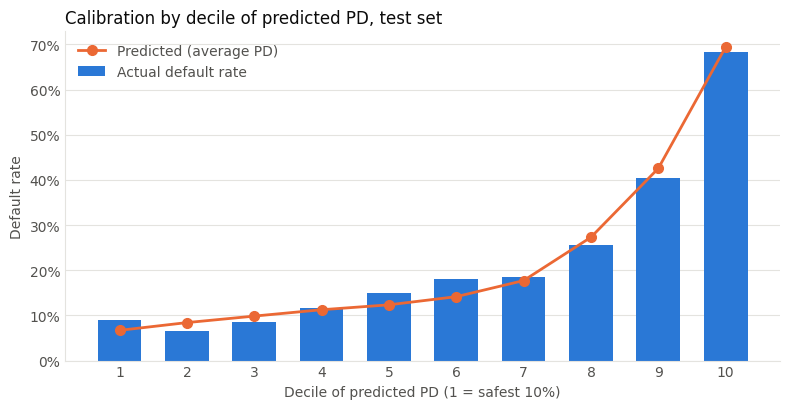

In [6]:
plot_calibration(calibration, "test set")
plt.show()

- **Predicted and actual default rates are within 4 percentage points in every decile.** Overall: 21.96% predicted vs 22.12% actual.
- **The riskiest 10% are predicted at 69% and actually default at 68%,** so the model is accurate where it matters most.
- **The safest 30% (PDs of 4–11%) aren't ranked well among themselves:** decile 1 actually defaults *more* (9.0%) than decile 2 (6.4%).
  The model knows these customers are low risk, but can't tell which of them is lowest. They mostly look identical (never late, revolving).
- Deciles 5–6 are slightly **under-predicted** (by 2.5–3.9 points). That's the zone where clean-history defaulters hide. It's worth tracking in monitoring.

## 5. Summary for the credit committee

> **What it is:** a 9-variable behavioural scorecard (scores 437–575, higher = safer) predicting which credit card customers
> will miss next month's payment. It is built mostly on recent repayment status, payment amounts and credit limit.
>
> **Does it rank risk well?** Yes. On 9,000 customers it has never seen, **Gini is 0.52 and KS is 0.40**. Customers scoring 517 or below
> (26% of the book) contain **58% of all defaulters**.
>
> **Are its probabilities right?** Yes. Predicted default rates are within 4 points of actual in every risk decile, and 22.0% vs 22.1% overall.
>
> **Is it stable?** Mostly. Test Gini is 3.5 points below train, just inside the "watch" zone. That is partly sampling noise, partly mild
> over-fitting of the bins. It isn't a blocker, but performance should be tracked from the first months of use.
>
> **Main limitation:** about a third of defaulters have a clean recent history and score like good customers. No behavioural
> scorecard can catch them; other data (income, bureau) would be needed.